In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns in pandas output
pd.set_option("display.max_columns", None)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
# load the dataset
df = pd.read_csv("../data/raw/train.csv")  
# Display first five records
df.head()


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [6]:
df.shape

(913000, 4)

In [7]:
number_of_rows = df.shape[0]
number_of_columns = df.shape[1]

print("Total records:", number_of_rows)
print("Total columns:", number_of_columns)

Total records: 913000
Total columns: 4


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 27.9 MB


In [9]:
missing_values = df.isnull().sum()

print(missing_values)

date     0
store    0
item     0
sales    0
dtype: int64


In [10]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [11]:
# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

# Check the data type
df["date"].dtype

dtype('<M8[us]')

In [13]:
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Total unique dates:", df["date"].nunique())

First date: 2013-01-01 00:00:00
Last date: 2017-12-31 00:00:00
Total unique dates: 1826


In [14]:
df = df.sort_values(by="date").reset_index(drop=True)

print("Is data chronologically sorted:", df["date"].is_monotonic_increasing)

Is data chronologically sorted: True


In [15]:
df["sales"].describe()

count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

In [16]:
average_sales = df["sales"].mean()
median_sales = df["sales"].median()
sales_std = df["sales"].std()
minimum_sales = df["sales"].min()
maximum_sales = df["sales"].max()

print("Average sales:", average_sales)
print("Median sales:", median_sales)
print("Standard deviation:", sales_std)
print("Minimum sales:", minimum_sales)
print("Maximum sales:", maximum_sales)

Average sales: 52.250286966046005
Median sales: 47.0
Standard deviation: 28.801143603517097
Minimum sales: 0
Maximum sales: 231


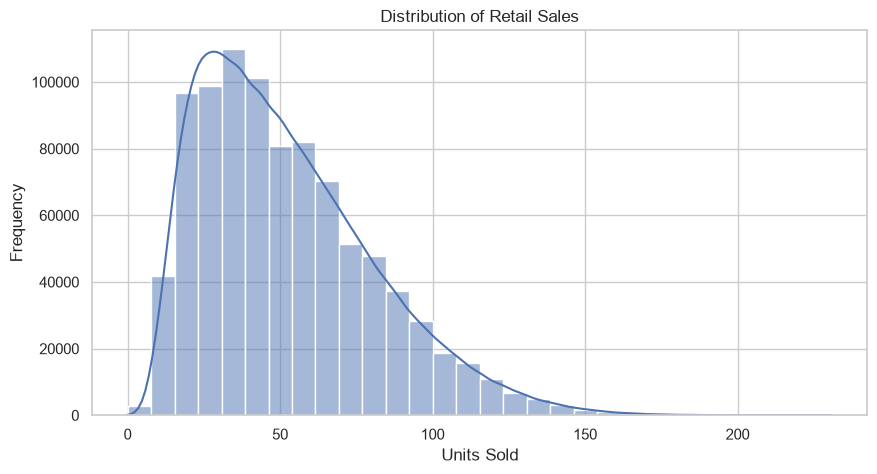

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(df["sales"], bins=30, kde=True)

plt.title("Distribution of Retail Sales")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.show()

In [18]:
# Calculate total sales for each date
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales.head()

,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


In [19]:
print("Dataset shape:", daily_sales.shape)
print("Number of unique dates:", daily_sales["date"].nunique())

daily_sales.describe()

Dataset shape: (1826, 2)
Number of unique dates: 1826


,date,sales
count,1826,1826.000000
mean,2015-07-02 12:00:00,26125.143483
min,2013-01-01 00:00:00,11709.000000
25%,2014-04-02 06:00:00,21195.000000
50%,2015-07-02 12:00:00,25839.500000
75%,2016-09-30 18:00:00,30779.500000
max,2017-12-31 00:00:00,44936.000000
std,NaN,6418.270181


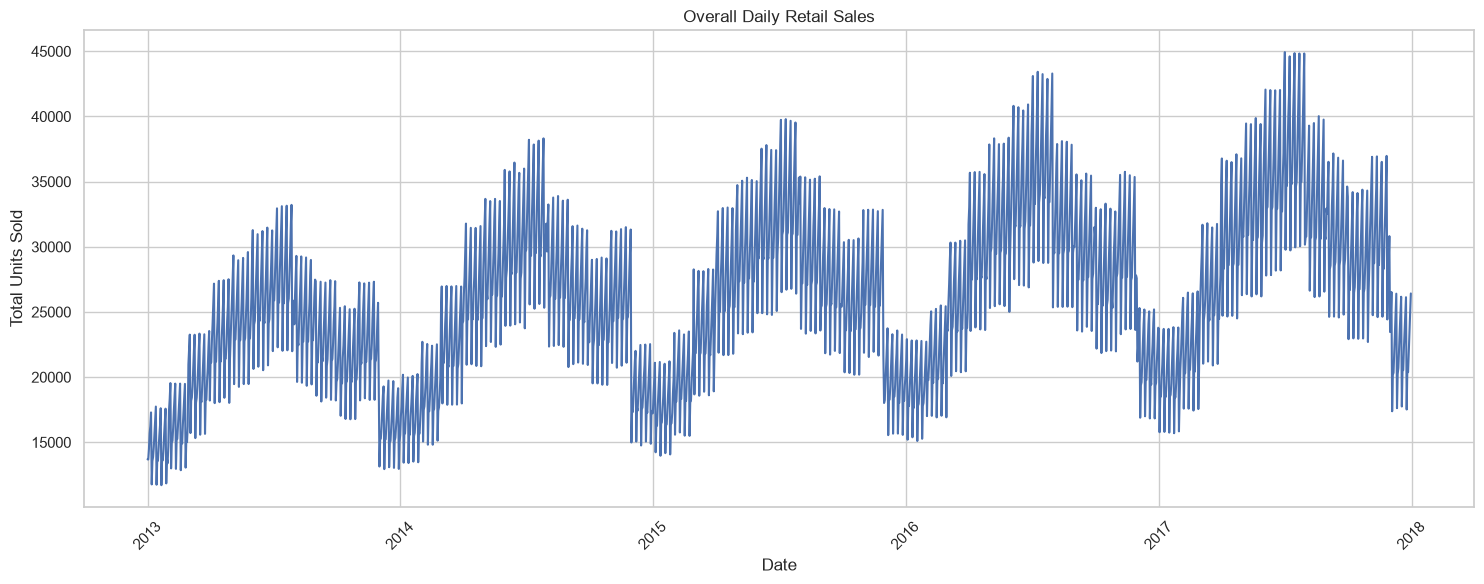

In [20]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"]
)

plt.title("Overall Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
number_of_stores = df["store"].nunique()
number_of_products = df["item"].nunique()

print("Total stores:", number_of_stores)
print("Total unique products:", number_of_products)

Total stores: 10
Total unique products: 50


In [22]:
sales_per_store = df.groupby("store")["sales"].sum().sort_values(
    ascending=False
)

print(sales_per_store)

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64


In [23]:
sales_per_product = df.groupby("item")["sales"].sum().sort_values(
    ascending=False
)

print(sales_per_product.head(10))

item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
Name: sales, dtype: int64


In [24]:
number_of_combinations = df.groupby(["store", "item"]).ngroups

print("Total store-product combinations:", number_of_combinations)

Total store-product combinations: 500


In [29]:
observations_per_combination = (
    df.groupby(["store", "item"])
    .size()
)

print("Minimum observations:", observations_per_combination.min())
print("Maximum observations:", observations_per_combination.max())
print("Average observations:", observations_per_combination.mean())

print("\nNumber of combinations with incomplete records:",(observations_per_combination != df["date"].nunique()).sum())

Minimum observations: 1826
Maximum observations: 1826
Average observations: 1826.0

Number of combinations with incomplete records: 0


In [30]:
duplicate_time_series_records = df.duplicated(
    subset=["date", "store", "item"]
).sum()

print("Duplicate date-store-item records:",duplicate_time_series_records)

Duplicate date-store-item records: 0


In [31]:
print("========== DATASET INSPECTION SUMMARY ==========")

print("Total records:", len(df))
print("Total stores:", df["store"].nunique())
print("Total products:", df["item"].nunique())
print("Unique dates:", df["date"].nunique())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())
print("Duplicate time-series keys:", duplicate_time_series_records)
print("Date range:", df["date"].min(), "to", df["date"].max())

print("================================================")

========== DATASET INSPECTION SUMMARY ==========
Total records: 913000
Total stores: 10
Total products: 50
Unique dates: 1826
Missing values: 0
Duplicate records: 0
Duplicate time-series keys: 0
Date range: 2013-01-01 00:00:00 to 2017-12-31 00:00:00
